FloatProgress(value=0.0, description='0% done ', max=300.0)

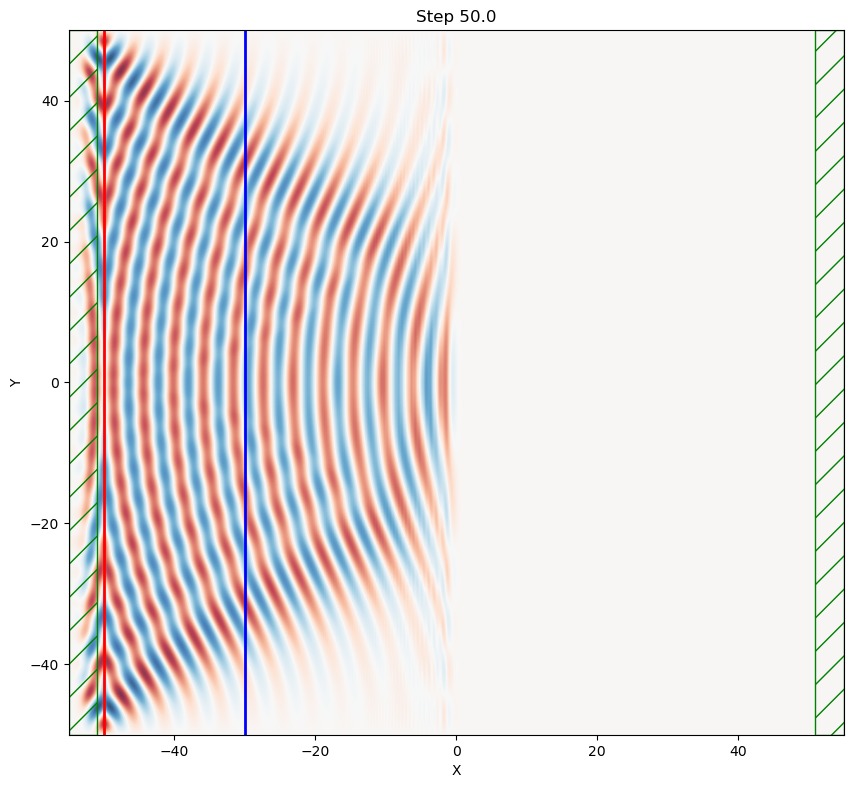

Ez data: (1000,)


/tmp/ipykernel_514007/185580321.py:65: RuntimeWarning: invalid value encountered in divide
  IAiry_norm = Idata / np.sum(Idata)


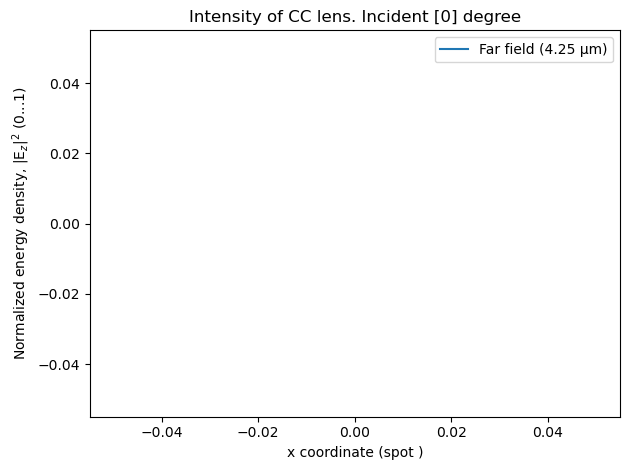

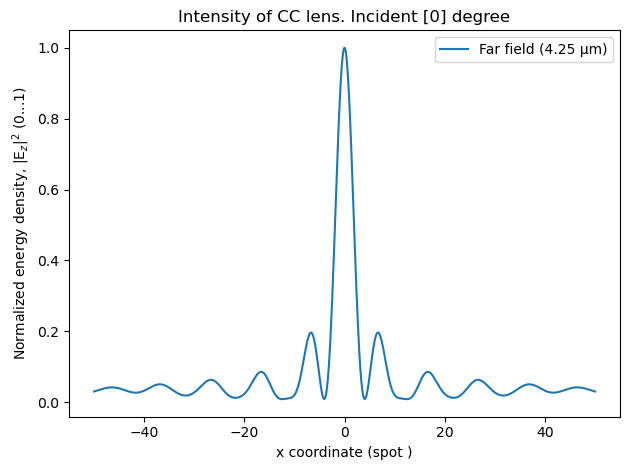

norm: nan norm_dtf: 0.012415360881944736
I_Airy_max 0.06147341645101277
Shtresl: 0.2019630858134971


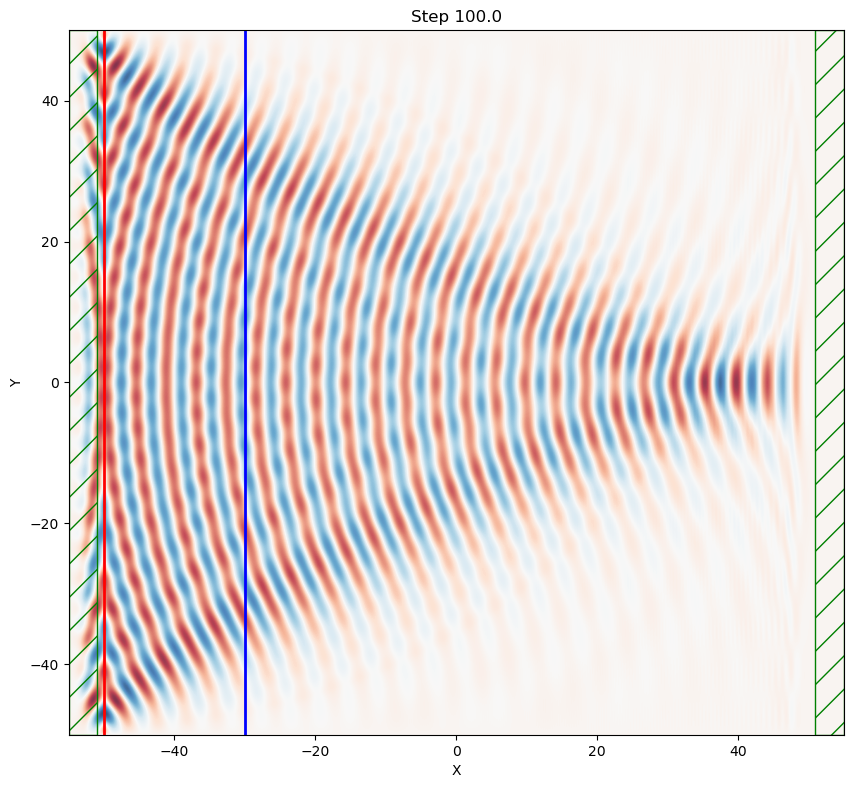

Ez data: (1000,)


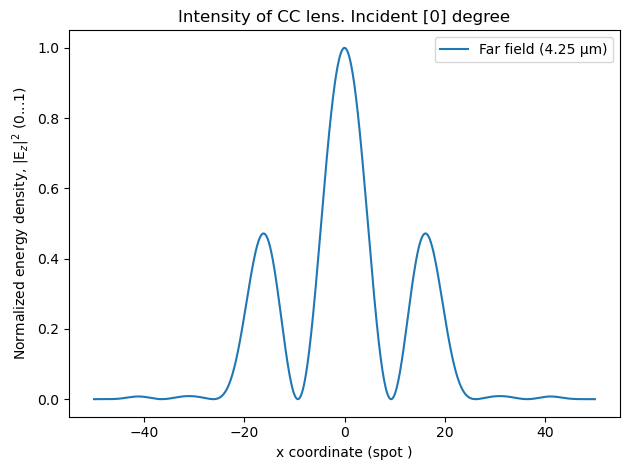

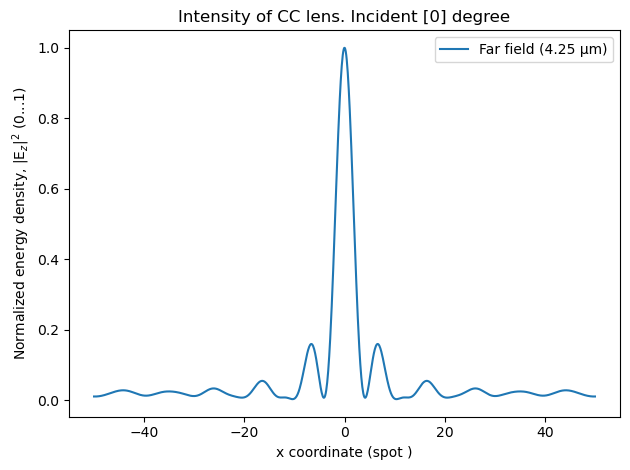

norm: 0.006040721151490892 norm_dtf: 0.015337946314655525
I_Airy_max 0.06147341645101277
Shtresl: 0.24950535044490493


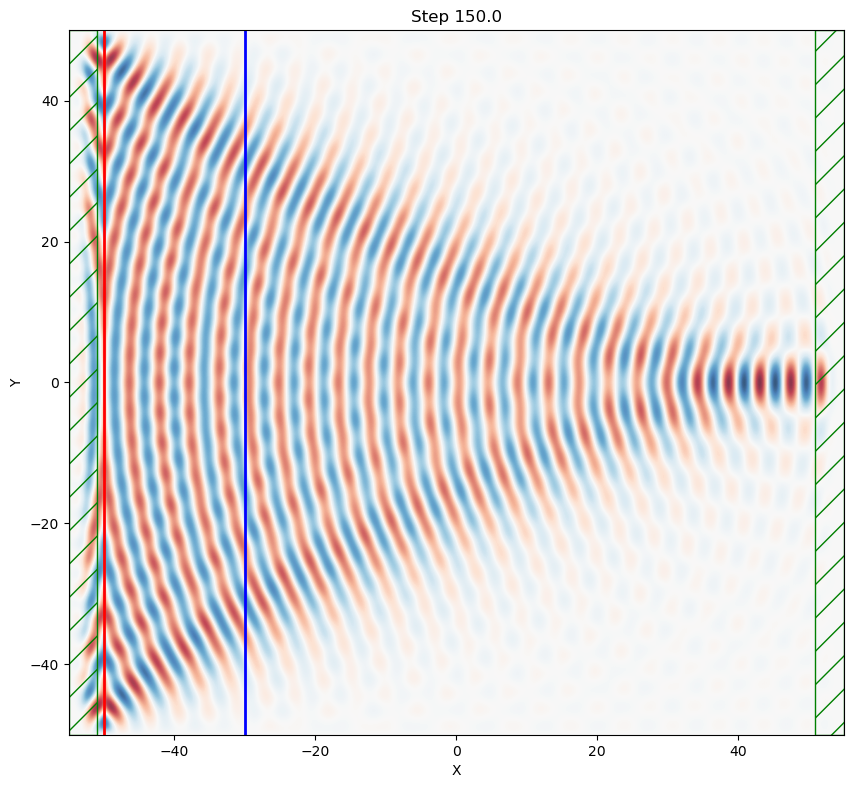

Ez data: (1000,)


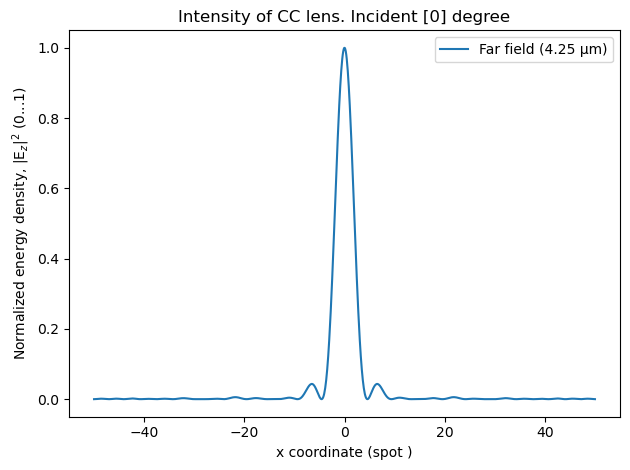

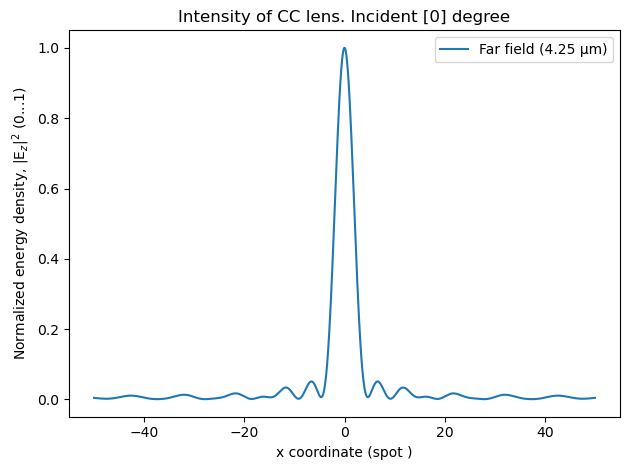

norm: 0.022689727784316664 norm_dtf: 0.019420863692684368
I_Airy_max 0.06147341645101277
Shtresl: 0.3159229601003315


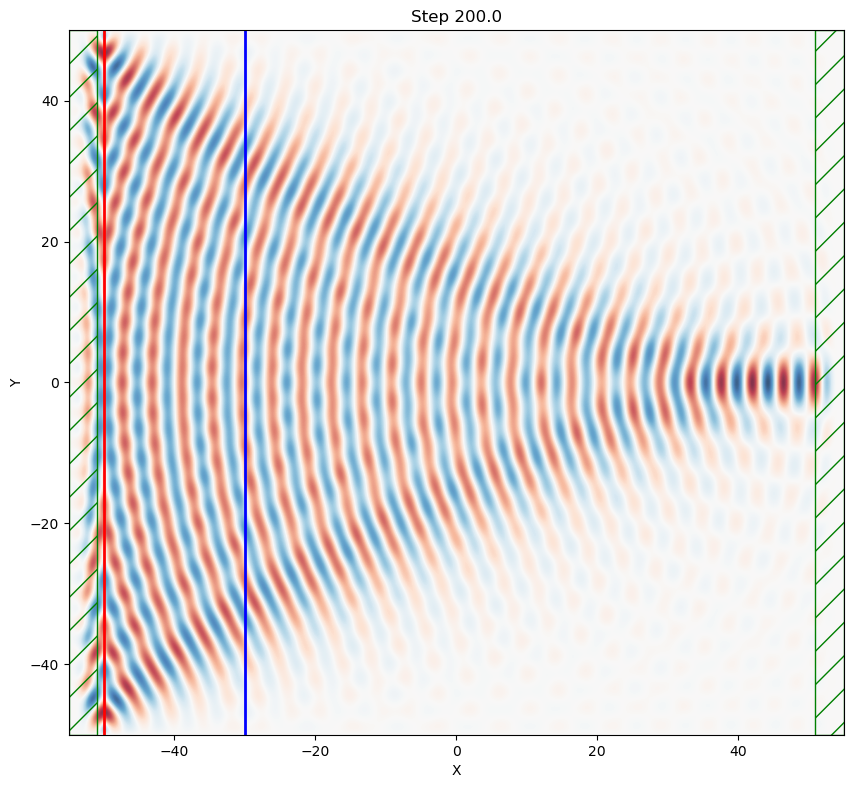

Ez data: (1000,)


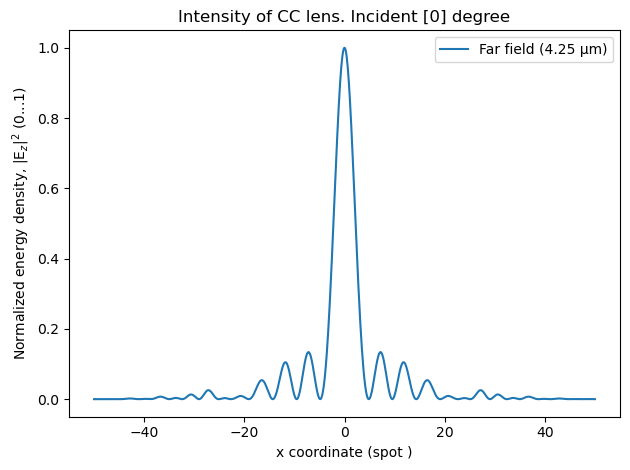

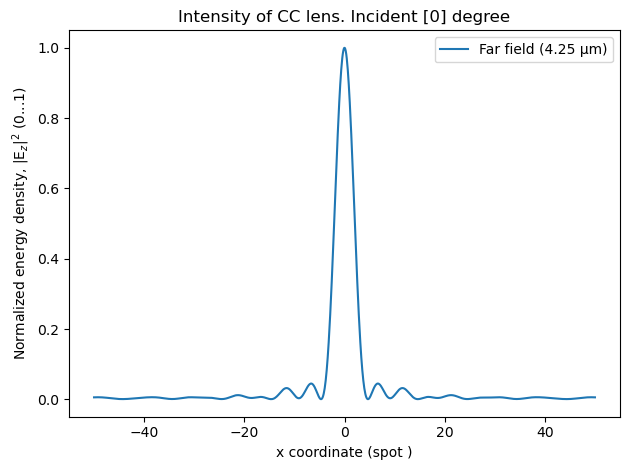

norm: 0.016370873385775735 norm_dtf: 0.020364100053877027
I_Airy_max 0.06147341645101277
Shtresl: 0.3312667691099431


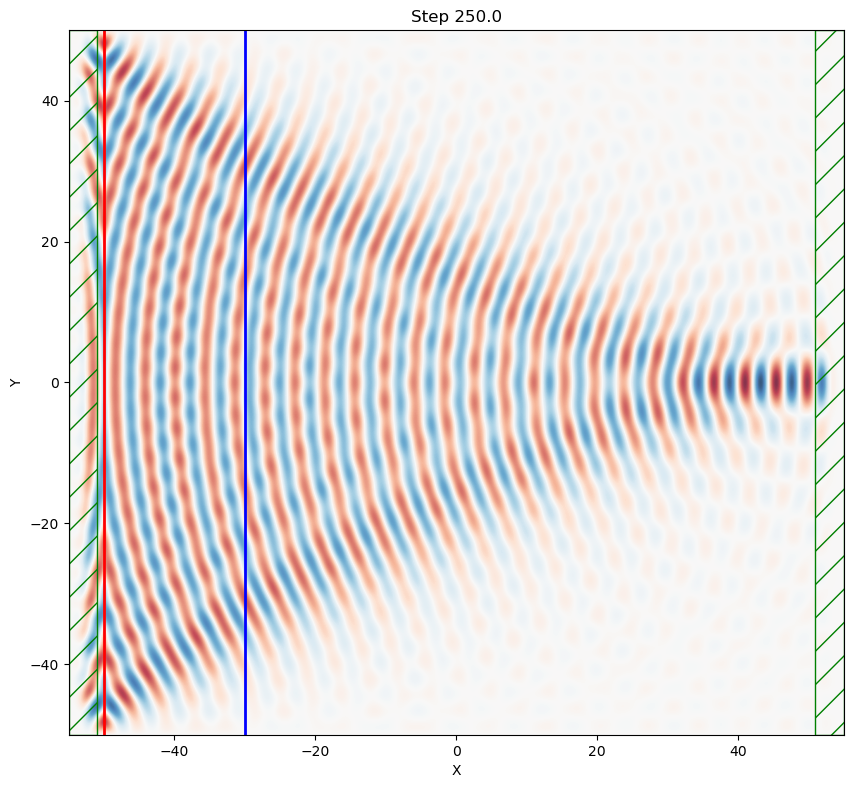

Ez data: (1000,)


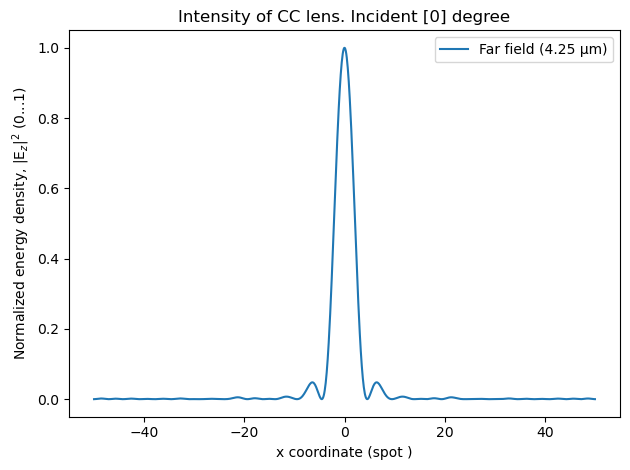

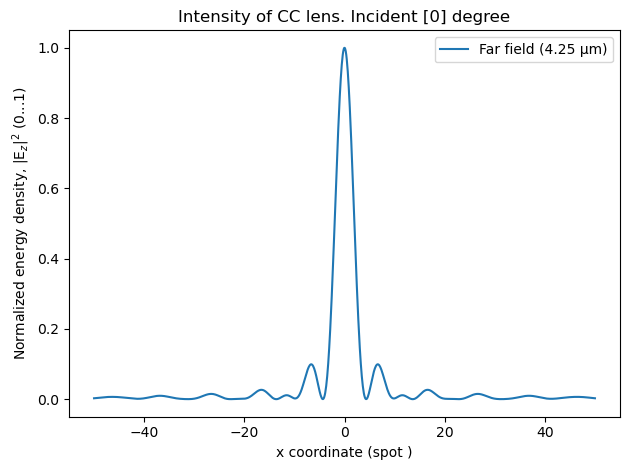

norm: 0.021823512961579587 norm_dtf: 0.0197959636253031
I_Airy_max 0.06147341645101277
Shtresl: 0.32202478352700964


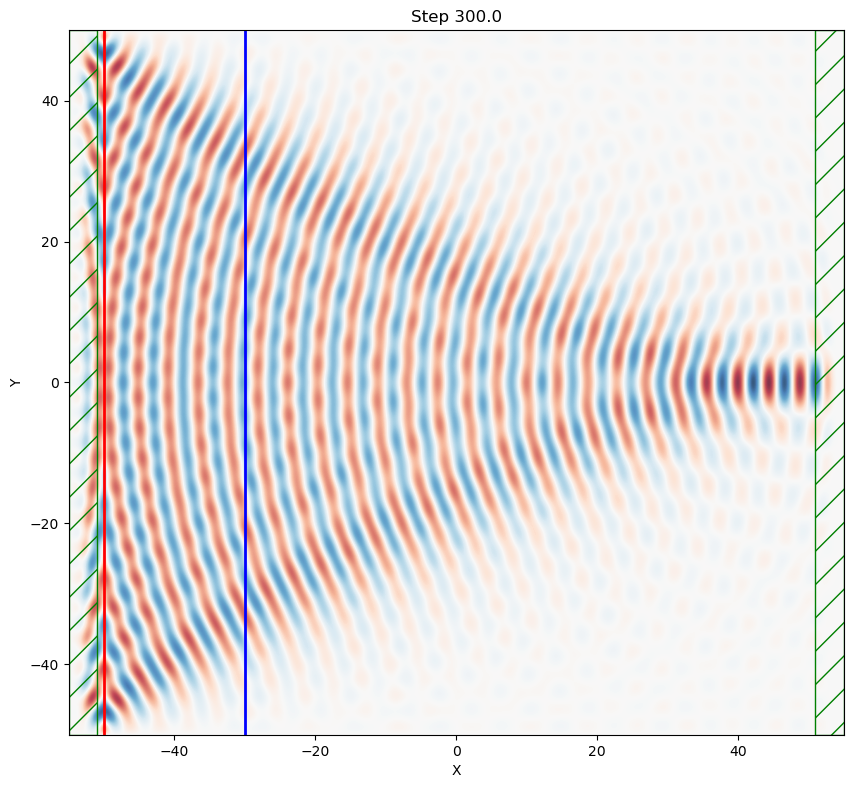

Ez data: (1000,)


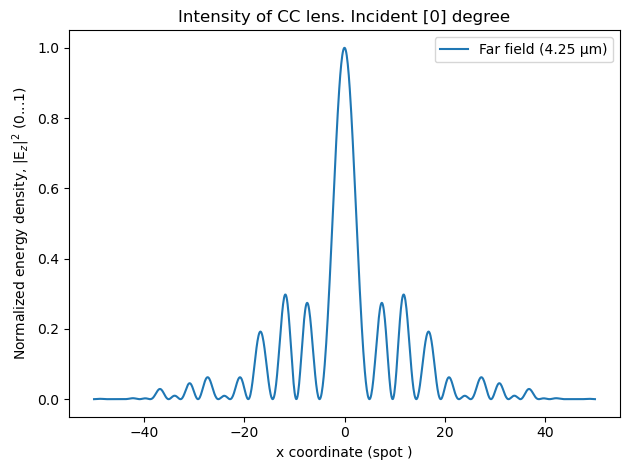

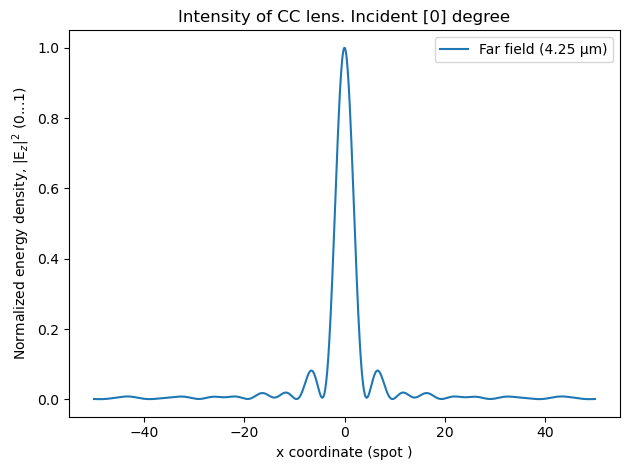

norm: 0.010834518178645768 norm_dtf: 0.019960721867921742
I_Airy_max 0.06147341645101277
Shtresl: 0.3247049378462337


In [4]:
import meep as mp
import numpy as np
import conf
import matplotlib.pyplot as plt
from lib import numpy_functions as nf 
from lib import my_sources

mp.verbosity(0)
cell = mp.Vector3(x = 110.0, y = 100.0)

# src = mp.Source(
#     src=mp.GaussianSource(frequency=conf.inc_fcen, fwidth=conf.inc_df),
#     component=mp.Ez,
#     center=mp.Vector3(-100 / 2, 0, 0),
#     size=mp.Vector3(0, 100, 0),
#     amp_func=lens_phase,
# )

IAiry_source_obj = my_sources.FocusedPlaneWaveSource(frequency=conf.inc_fcen, dfreq=conf.inc_df, y=100, center = mp.Vector3(-100/2,0,0), focus_point=mp.Vector3(x=100, y=0))
IAiry_source = IAiry_source_obj.get_sources()

# sources_obj = my_sources.KvectorSource(frequency=conf.inc_fcen, dfreq = conf.inc_df, y=100, center = mp.Vector3(-100/2, 0,0), angle = 20)
# sources = sources_obj.get_sources()

# geometry = [mp.Block(
#     material=conf.in_material,
#     size=mp.Vector3(50, mp.inf, 0),
#     center=mp.Vector3(-100 / 2),
# )]

sim = mp.Simulation(
    cell_size=cell,
    boundary_layers=[mp.PML(thickness=conf.pml, direction=mp.X, side=mp.ALL)],
    sources=IAiry_source,
    resolution=10
)

# dtf_obj = sim.add_flux(conf.inc_fcen, 0, 1,
#              mp.FluxRegion(center=mp.Vector3(-100/2 + 20,0,0),
#                            size=mp.Vector3(0, 100, 0)))

NearRegions = [mp.Near2FarRegion(center=mp.Vector3(-100/2 + 20,0,0), size=mp.Vector3(0, 100, 0))]
near2far_obj = sim.add_near2far(
    conf.inc_fcen,  # центральная частота
    conf.inc_df,    # ширина спектра
    conf.inc_nfreq, # дискретность частот
    NearRegions[0],
)

ff_res = float(10)


def plot_field(sim):
    plt.figure(figsize=(10, 10))
    sim.plot2D(fields=mp.Ez)
    plt.title(f"Step {sim.meep_time():.1f}")
    plt.show()
    
    ez_data = sim.get_array(component=mp.Ez,
                        center=mp.Vector3(50,0,0),
                        size=mp.Vector3(0, 100, 0)) 
    
    print(f"Ez data: {ez_data.shape}")
    Idata = ez_data**2
    IAiry_norm = Idata / np.sum(Idata)
    IAiry_norm_scale = IAiry_norm / np.max(IAiry_norm)
    nf.get_plot_intensity(100, IAiry_norm_scale, angle = conf.angle_list, relation='abs')
    
    # ez_data_dft = sim.get_dft_array(    
    #     dtf_obj,
    #     num_freq = 0,
    #     component=mp.Ez)
    
    
    far_field = sim.get_farfields(
        near2far_obj,
        ff_res,
        center=mp.Vector3(x=50, y=0),
        size=mp.Vector3(0, 100, 0)
    )
    
    Idase_dft = np.abs(far_field["Ez"])**2
    IAiry_norm_dft = Idase_dft / np.sum(Idase_dft)
    IAiry_norm_dft_scale = IAiry_norm_dft / np.max(IAiry_norm_dft)
    
    nf.get_plot_intensity(100, IAiry_norm_dft_scale, angle = conf.angle_list, relation='abs')
    
    print(f"norm: {max(IAiry_norm)} norm_dtf: {max(IAiry_norm_dft)}")

sim.run(mp.at_every(50, plot_field), until=300)